In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


In [2]:
DATA_DIR = Path("../myntradataset")

products = pd.read_csv(
    DATA_DIR / "styles.csv",
    engine="python",
    on_bad_lines="skip"
)

print("Dataset shape:", products.shape)
print(products.columns.tolist())
products.head()

Dataset shape: (44424, 10)
['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName']


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


masterCategory
Apparel           21397
Accessories       11274
Footwear           9219
Personal Care      2403
Free Items          105
Sporting Goods       25
Home                  1
Name: count, dtype: int64


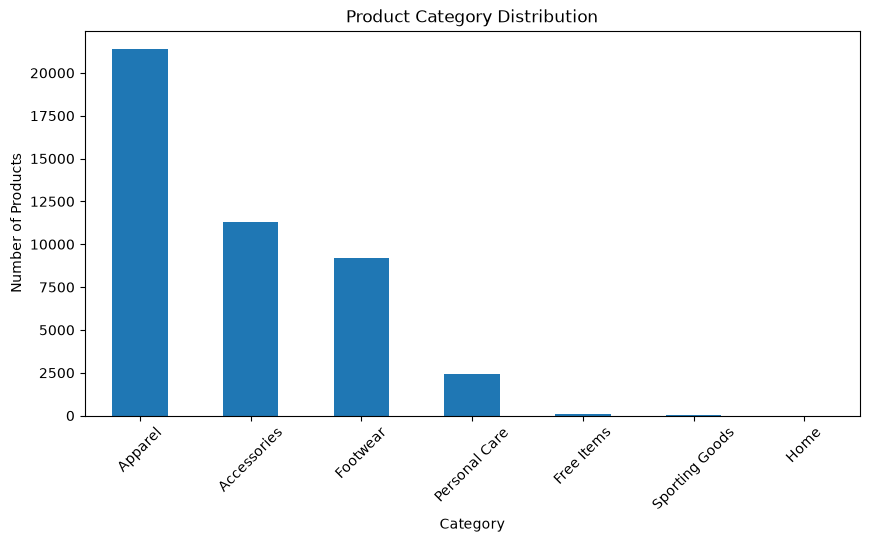

In [3]:
category_counts = products["masterCategory"].value_counts()

print(category_counts)

category_counts.plot(
    kind="bar",
    figsize=(10, 5),
    title="Product Category Distribution"
)

plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45)
plt.show()

In [4]:
IMAGE_DIR = DATA_DIR / "images"

products["image_path"] = products["id"].apply(
    lambda x: IMAGE_DIR / f"{x}.jpg"
)

products["image_exists"] = products["image_path"].apply(
    lambda x: x.exists()
)

products = products[products["image_exists"]].copy()

print("Available images:", len(products))

Available images: 44419


In [5]:
rare_products = products[
    products["masterCategory"].isin(["Free Items", "Sporting Goods"])
]

print(rare_products["masterCategory"].value_counts())

masterCategory
Free Items        105
Sporting Goods     25
Name: count, dtype: int64


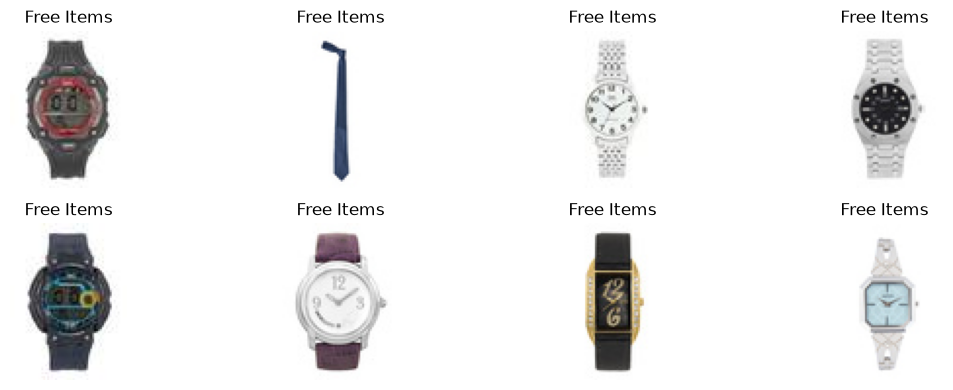

In [6]:
plt.figure(figsize=(12, 4))

for i, (_, row) in enumerate(rare_products.head(8).iterrows()):
    img = Image.open(row["image_path"]).convert("RGB")

    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title(row["masterCategory"])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
apparel = products[
    products["masterCategory"] == "Apparel"
].sample(n=2000, random_state=42)

print("Training images:", len(apparel))

Training images: 2000


In [10]:
IMG_SIZE = 64

images = []

for path in apparel["image_path"]:
    try:
        img = Image.open(path).convert("RGB")
        img = img.resize((IMG_SIZE, IMG_SIZE))
        images.append(np.array(img))
    except:
        continue

images = np.array(images, dtype="float32") / 255.0

print("Image dataset shape:", images.shape)

Image dataset shape: (2000, 64, 64, 3)


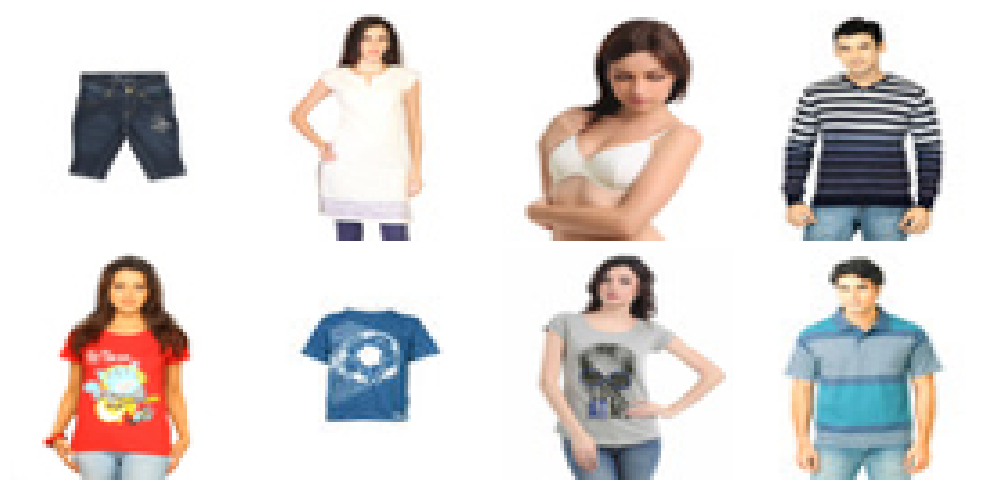

In [11]:
plt.figure(figsize=(10, 5))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
from tensorflow.keras.layers import Input, Conv2D, Flatten, Dense, Reshape, Conv2DTranspose
from tensorflow.keras.models import Model

latent_dim = 128

encoder_input = Input(shape=(64, 64, 3))

x = Conv2D(32, 3, strides=2, activation="relu", padding="same")(encoder_input)
x = Conv2D(64, 3, strides=2, activation="relu", padding="same")(x)
x = Flatten()(x)

z_mean = Dense(latent_dim)(x)
z_log_var = Dense(latent_dim)(x)

print("Encoder created successfully!")

Encoder created successfully!


In [13]:
import tensorflow as tf

def sampling(args):
    z_mean, z_log_var = args

    epsilon = tf.random.normal(
        shape=tf.shape(z_mean)
    )

    return z_mean + tf.exp(0.5 * z_log_var) * epsilon

from tensorflow.keras.layers import Lambda

z = Lambda(sampling)([z_mean, z_log_var])

print("Sampling layer created!")


Sampling layer created!


In [17]:
class VAE(tf.keras.Model):

    def __init__(self, encoder, decoder):
        super().__init__()

        self.encoder = encoder
        self.decoder = decoder

    def train_step(self, data):

        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:

            z_mean, z_log_var, z = self.encoder(data)

            reconstruction = self.decoder(z)

            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    tf.keras.losses.binary_crossentropy(
                        data, reconstruction
                    ),
                    axis=(1, 2)
                )
            )

            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1 + z_log_var
                    - tf.square(z_mean)
                    - tf.exp(z_log_var),
                    axis=1
                )
            )

            total_loss = reconstruction_loss + kl_loss

        gradients = tape.gradient(
            total_loss, self.trainable_weights
        )

        self.optimizer.apply_gradients(
            zip(gradients, self.trainable_weights)
        )

        return {
            "loss": total_loss,
            "reconstruction_loss": reconstruction_loss,
            "kl_loss": kl_loss
        }

In [20]:
vae = VAE(encoder, decoder)

vae.compile(
    optimizer=tf.keras.optimizers.Adam()
)

print("VAE compiled successfully!")

VAE compiled successfully!


In [21]:
history = vae.fit(
    images,
    epochs=20,
    batch_size=32,
    shuffle=True
)

Epoch 1/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 18s 241ms/step - kl_loss: 17.6231 - loss: 1723.4719 - reconstruction_loss: 1705.8489
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 195ms/step - kl_loss: 30.3855 - loss: 1453.6245 - reconstruction_loss: 1423.2390
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 196ms/step - kl_loss: 36.9013 - loss: 1441.5031 - reconstruction_loss: 1404.6018
Epoch 4/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 195ms/step - kl_loss: 35.2048 - loss: 1221.8887 - reconstruction_loss: 1186.6838
Epoch 5/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 194ms/step - kl_loss: 32.4772 - loss: 1371.5972 - reconstruction_loss: 1339.1199
Epoch 6/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 193ms/step - kl_loss: 42.7529 - loss: 1237.5043 - reconstruction_loss: 1194.7515
Epoch 7/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 193ms/step - kl_loss: 46.7012 - loss: 1275.5654 - reconstruction_loss: 1228.8643
Epoch 8/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 201ms/step - kl_loss: 45.3636 - loss: 1156.0682 - reconstruction_loss: 1110.7046
Epoch 9/20
63/63

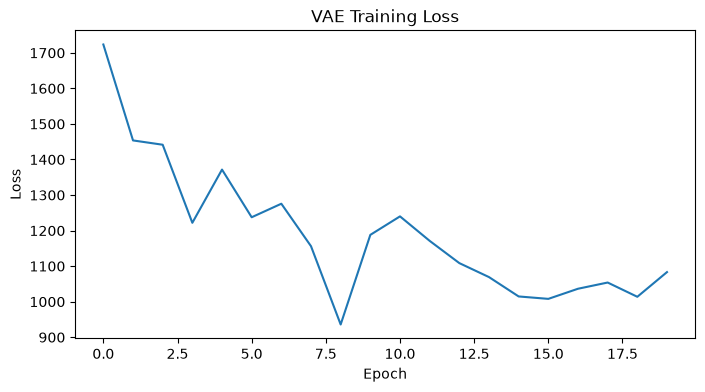

In [22]:
plt.figure(figsize=(8, 4))

plt.plot(history.history["loss"])

plt.title("VAE Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step


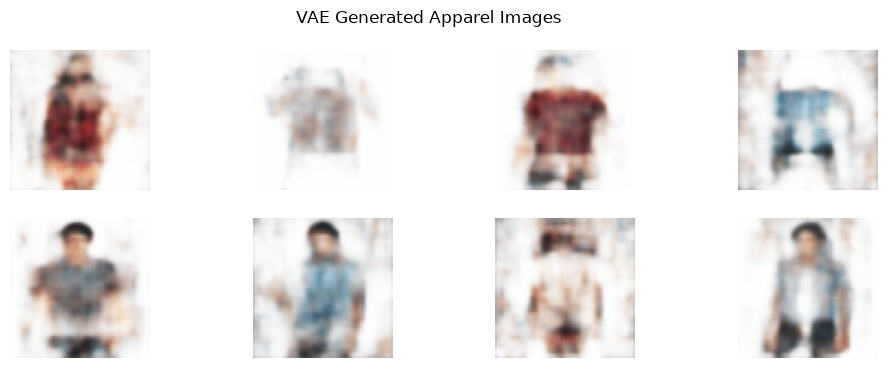

In [23]:
import numpy as np

random_latent = np.random.normal(
    size=(8, latent_dim)
).astype("float32")

generated_images = decoder.predict(random_latent)

plt.figure(figsize=(12, 4))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(generated_images[i])
    plt.axis("off")

plt.suptitle("VAE Generated Apparel Images")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step


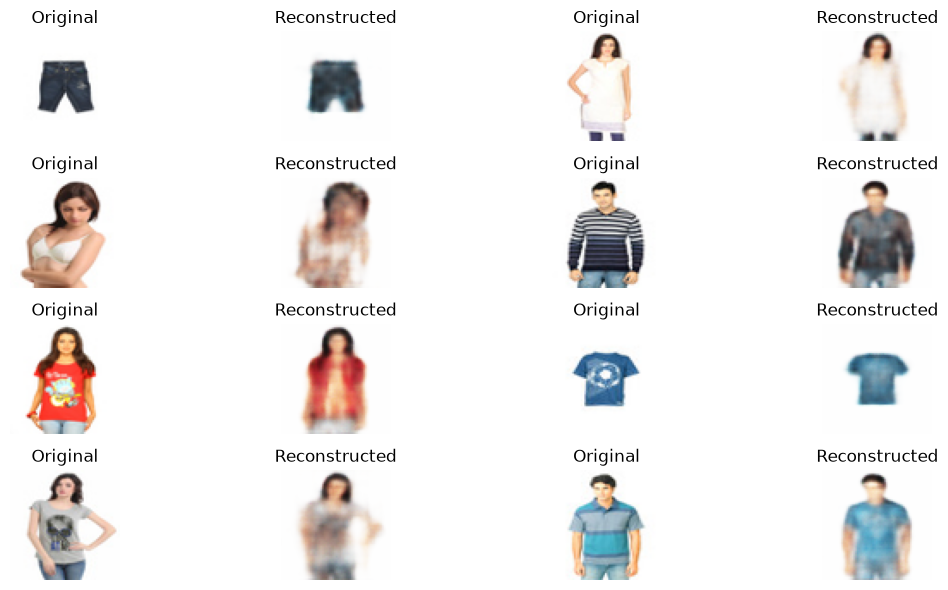

In [24]:
sample_images = images[:8]

z_mean, z_log_var, z = encoder.predict(sample_images)

reconstructed_images = decoder.predict(z)

plt.figure(figsize=(12, 6))

for i in range(8):
    # Original
    plt.subplot(4, 4, 2*i + 1)
    plt.imshow(sample_images[i])
    plt.title("Original")
    plt.axis("off")

    # Reconstructed
    plt.subplot(4, 4, 2*i + 2)
    plt.imshow(reconstructed_images[i])
    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 315ms/step


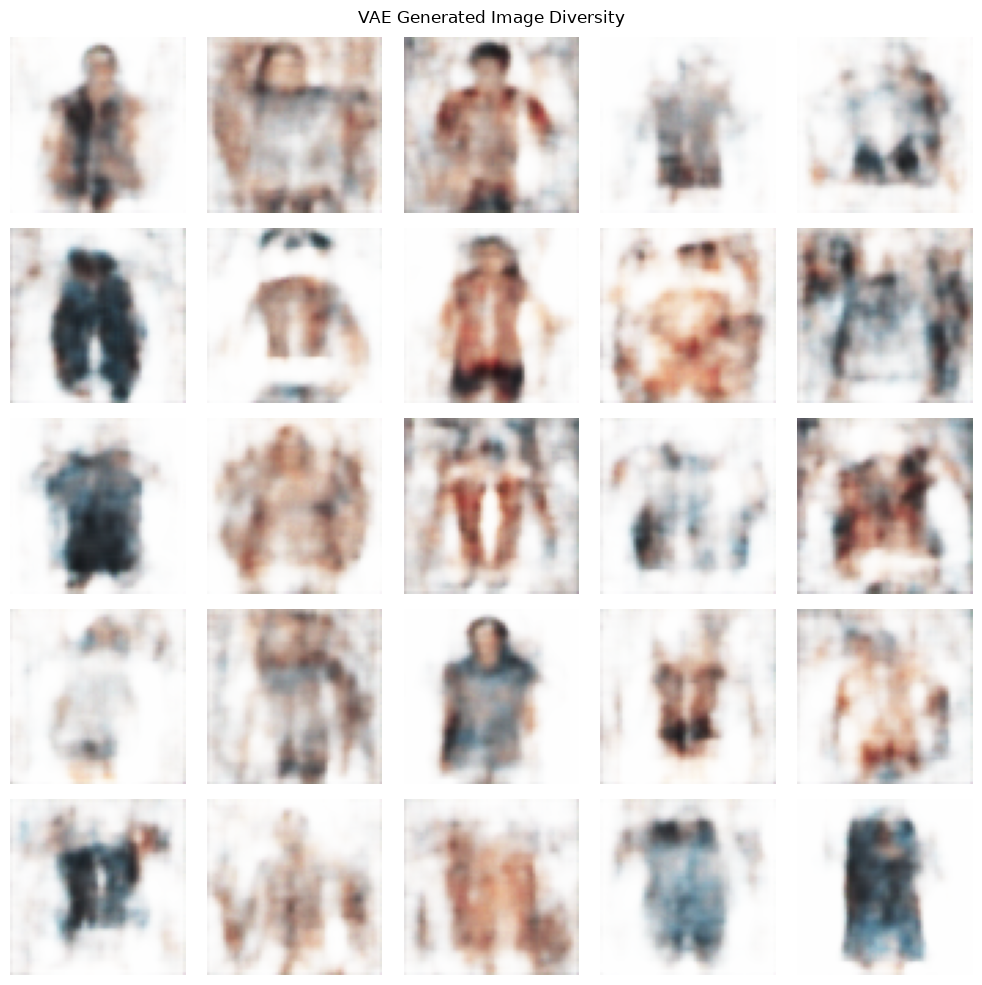

In [25]:
random_latent = np.random.normal(
    size=(25, latent_dim)
).astype("float32")

generated_images = decoder.predict(random_latent)

plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(generated_images[i])
    plt.axis("off")

plt.suptitle("VAE Generated Image Diversity")
plt.tight_layout()
plt.show()

In [26]:
from pathlib import Path
from PIL import Image

OUTPUT_DIR = Path("../data/vae_generated_apparel")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for i, img in enumerate(generated_images):
    img = np.clip(img * 255, 0, 255).astype("uint8")

    Image.fromarray(img).save(
        OUTPUT_DIR / f"apparel_generated_{i+1}.jpg"
    )

print("Generated images saved:", len(generated_images))
print("Location:", OUTPUT_DIR)

Generated images saved: 25
Location: ..\data\vae_generated_apparel


In [27]:
from pathlib import Path

generated_dir = Path("../data/vae_generated_apparel")

generated_files = list(generated_dir.glob("*.jpg"))

print("Generated images:", len(generated_files))
print("First 5 files:")

for file in generated_files[:5]:
    print(file.name)

Generated images: 25
First 5 files:
apparel_generated_1.jpg
apparel_generated_10.jpg
apparel_generated_11.jpg
apparel_generated_12.jpg
apparel_generated_13.jpg


In [28]:
import tensorflow as tf

cnn_model = tf.keras.models.load_model(
    "../models/retail_cnn_day6.keras"
)

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,916,244 (37.83 MB)

 Trainable params: 3,305,414 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,610,830 (25.22 MB)

In [29]:
print("CNN input shape:", cnn_model.input_shape)
print("CNN output shape:", cnn_model.output_shape)

print("Generated image count:", len(generated_files))


CNN input shape: (None, 128, 128, 3)
CNN output shape: (None, 6)
Generated image count: 25


In [30]:
from PIL import Image
import numpy as np

synthetic_images = []

for file in generated_files:
    img = Image.open(file).convert("RGB")
    img = img.resize((128, 128))

    synthetic_images.append(np.array(img))

synthetic_images = np.array(
    synthetic_images, dtype="float32"
) / 255.0

print("Synthetic dataset shape:", synthetic_images.shape)

Synthetic dataset shape: (25, 128, 128, 3)


In [31]:
predictions = cnn_model.predict(synthetic_images)

predicted_classes = np.argmax(predictions, axis=1)

unique, counts = np.unique(
    predicted_classes, return_counts=True
)

print("Predicted class distribution:")

for cls, count in zip(unique, counts):
    print(f"Class {cls}: {count} images")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 406ms/step
Predicted class distribution:
Class 0: 7 images
Class 1: 15 images
Class 4: 3 images


In [32]:
for i in range(10):
    print(
        f"Image {i+1}: "
        f"Predicted class = {predicted_classes[i]}, "
        f"Confidence = {predictions[i].max():.2%}"
    )

Image 1: Predicted class = 1, Confidence = 69.45%
Image 2: Predicted class = 1, Confidence = 70.64%
Image 3: Predicted class = 1, Confidence = 77.76%
Image 4: Predicted class = 0, Confidence = 52.04%
Image 5: Predicted class = 0, Confidence = 54.78%
Image 6: Predicted class = 1, Confidence = 87.02%
Image 7: Predicted class = 1, Confidence = 58.60%
Image 8: Predicted class = 0, Confidence = 98.29%
Image 9: Predicted class = 1, Confidence = 88.60%
Image 10: Predicted class = 1, Confidence = 72.42%


In [34]:
import pandas as pd

results = pd.DataFrame({
    "Image": range(1, 26),
    "Predicted_Class": predicted_classes,
    "Predicted_Category": [
        ["Accessories", "Apparel", "Footwear",
         "Free Items", "Personal Care", "Sporting Goods"][i]
        for i in predicted_classes
    ],
    "Confidence": predictions.max(axis=1)
})

results.to_csv(
    "../data/day11_vae_predictions.csv",
    index=False
)

print(results.head(10))
print("\nResults saved successfully!")

   Image  Predicted_Class Predicted_Category  Confidence
0      1                1            Apparel    0.694486
1      2                1            Apparel    0.706393
2      3                1            Apparel    0.777640
3      4                0        Accessories    0.520359
4      5                0        Accessories    0.547796
5      6                1            Apparel    0.870244
6      7                1            Apparel    0.585992
7      8                0        Accessories    0.982938
8      9                1            Apparel    0.886036
9     10                1            Apparel    0.724184

Results saved successfully!


In [35]:
from collections import Counter

category_counts = Counter(results["Predicted_Category"])

print("VAE Evaluation Summary")
print("----------------------")
print("Total generated images:", len(generated_images))
print("Predicted as Apparel:", category_counts["Apparel"])
print("Apparel prediction rate:",
      f"{category_counts['Apparel'] / 25 * 100:.2f}%")
print("Unique predicted categories:", len(category_counts))

VAE Evaluation Summary
----------------------
Total generated images: 25
Predicted as Apparel: 15
Apparel prediction rate: 60.00%
Unique predicted categories: 3


In [36]:
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

encoder.save(MODEL_DIR / "day11_vae_encoder.keras")
decoder.save(MODEL_DIR / "day11_vae_decoder.keras")

print("Encoder and Decoder saved successfully!")

Encoder and Decoder saved successfully!
